# Practical 5 — Generative Adversarial Networks

**Enrollment:** BT24S05F007

## Aim
Study GAN architecture and train a small PyTorch GAN so the generator learns to invent samples that look like a known 2D distribution.

## Architecture
Noise vector → **Generator** → fake point → **Discriminator** → real/fake score.

The discriminator is trained to mark real points as 1 and fake points as 0. The generator is trained so its fakes score close to 1. Both networks improve because each one is the other's opponent.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cpu")


## Real data
Three Gaussian blobs form a simple “real” cloud. The GAN never sees labels; it only sees the point coordinates.


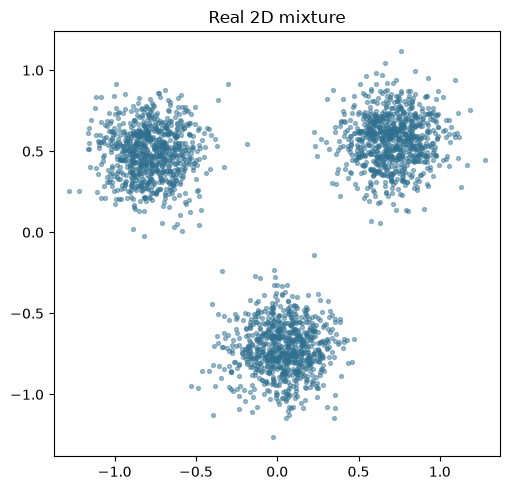

Real data shape: (2400, 2)


In [2]:
def make_blobs(count=2400):
    sizes = [count // 3, count // 3, count - 2 * (count // 3)]
    centers = [(-2.2, 1.4), (2.0, 1.6), (0.1, -2.0)]
    pieces = [
        np.random.normal(center, 0.45, size=(size, 2))
        for center, size in zip(centers, sizes)
    ]
    cloud = np.vstack(pieces).astype(np.float32)
    return cloud / 2.8

real_points = make_blobs()
real_tensor = torch.tensor(real_points, dtype=torch.float32)

plt.figure(figsize=(5.2, 5.0))
plt.scatter(real_points[:, 0], real_points[:, 1], s=8, alpha=0.45, c="#2f6f8f")
plt.title("Real 2D mixture")
plt.axis("equal")
plt.tight_layout()
plt.show()
print("Real data shape:", real_points.shape)


## Generator and discriminator


In [3]:
class PointGenerator(nn.Module):
    def __init__(self, noise_size=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(noise_size, 32),
            nn.LeakyReLU(0.2),
            nn.Linear(32, 32),
            nn.LeakyReLU(0.2),
            nn.Linear(32, 2),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.net(noise)


class PointDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.LeakyReLU(0.2),
            nn.Linear(32, 16),
            nn.LeakyReLU(0.2),
            nn.Linear(16, 1),
            nn.Sigmoid(),
        )

    def forward(self, points):
        return self.net(points)


noise_size = 4
generator = PointGenerator(noise_size).to(device)
discriminator = PointDiscriminator().to(device)
loss_fn = nn.BCELoss()
opt_g = torch.optim.Adam(generator.parameters(), lr=0.0015, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(discriminator.parameters(), lr=0.0015, betas=(0.5, 0.999))
print(generator)
print(discriminator)


PointGenerator(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=32, out_features=2, bias=True)
    (5): Tanh()
  )
)
PointDiscriminator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=16, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


## Adversarial training
Each step updates the discriminator on a real batch and a fake batch, then updates the generator so its fakes look real.


In [4]:
epochs = 900
batch = 96
history_d = []
history_g = []

for epoch in range(1, epochs + 1):
    index = torch.randint(0, real_tensor.shape[0], (batch,))
    real_batch = real_tensor[index]
    ones = torch.ones(batch, 1)
    zeros = torch.zeros(batch, 1)

    noise = torch.randn(batch, noise_size)
    fake_batch = generator(noise).detach()

    opt_d.zero_grad()
    real_score = discriminator(real_batch)
    fake_score = discriminator(fake_batch)
    d_loss = loss_fn(real_score, ones) + loss_fn(fake_score, zeros)
    d_loss.backward()
    opt_d.step()

    noise = torch.randn(batch, noise_size)
    opt_g.zero_grad()
    forged = generator(noise)
    trick_score = discriminator(forged)
    g_loss = loss_fn(trick_score, ones)
    g_loss.backward()
    opt_g.step()

    history_d.append(float(d_loss.item()))
    history_g.append(float(g_loss.item()))
    if epoch % 150 == 0:
        print(f"epoch {epoch:4d} | D {d_loss.item():.3f} | G {g_loss.item():.3f}")

print("Training finished.")


epoch  150 | D 1.178 | G 0.865
epoch  300 | D 1.518 | G 0.688


epoch  450 | D 1.349 | G 0.838
epoch  600 | D 1.312 | G 0.770


epoch  750 | D 1.372 | G 0.710
epoch  900 | D 1.349 | G 0.722
Training finished.


## Losses and generated cloud


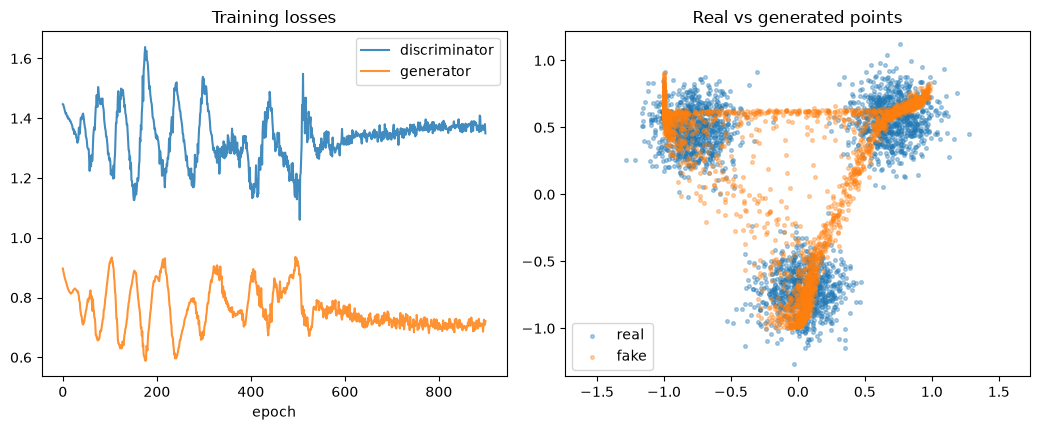

Fake mean: [-0.073  0.157]
Real mean: [-0.014  0.113]


In [5]:
with torch.no_grad():
    fake_points = generator(torch.randn(2400, noise_size)).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
axes[0].plot(history_d, label="discriminator", alpha=0.85)
axes[0].plot(history_g, label="generator", alpha=0.85)
axes[0].set_title("Training losses")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].scatter(real_points[:, 0], real_points[:, 1], s=7, alpha=0.35, label="real")
axes[1].scatter(fake_points[:, 0], fake_points[:, 1], s=7, alpha=0.35, label="fake")
axes[1].set_title("Real vs generated points")
axes[1].axis("equal")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Fake mean:", np.round(fake_points.mean(axis=0), 3))
print("Real mean:", np.round(real_points.mean(axis=0), 3))


## Conclusion
The generator never saw the original samples as a lookup table; it only received noise and a signal from the discriminator. After adversarial training, the fake cloud sits near the three real blobs, which is the basic GAN learning outcome.


## Run results

Outputs captured from the executed notebook.

```
Real data shape: (2400, 2)
```

```
PointGenerator(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=32, out_features=2, bias=True)
    (5): Tanh()
  )
)
PointDiscriminator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=16, out_features=1, bias=True)
    (5): Sigmoid()
  )
)
```

```
epoch  150 | D 1.178 | G 0.865
epoch  300 | D 1.518 | G 0.688
epoch  450 | D 1.349 | G 0.838
epoch  600 | D 1.312 | G 0.770
epoch  750 | D 1.372 | G 0.710
epoch  900 | D 1.349 | G 0.722
Training finished.
```

```
Fake mean: [-0.073  0.157]
Real mean: [-0.014  0.113]
```

**figure 1**

![figure 1](results/GenAI_Practical_05_fig1.png)

**figure 2**

![figure 2](results/GenAI_Practical_05_fig2.png)
